# Sales Prediction Using Python
**Oasis Infobyte Internship · Data Science · Task 5**

Goal: predict product **Sales** (thousands of units) from advertising spend (thousands of dollars) on
**TV**, **Radio** and **Newspaper**, and find out which channel drives sales the most.

Dataset: `Advertising.csv` (200 markets), the classic dataset from *An Introduction to Statistical
Learning*, also published on Kaggle.

Steps: EDA → scatter plots → correlation heatmap → train/test split → Linear Regression baseline →
Polynomial Regression and Random Forest → MAE / RMSE / R² → residual analysis → channel interpretation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data and run EDA

In [2]:
df = pd.read_csv("data/Advertising.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
print("Data types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Data types:
 TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values per column:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [4]:
df.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


No missing values or duplicates. TV budgets are much larger (up to ~$296k) than Radio (up to ~$50k)
and Newspaper (up to ~$114k).

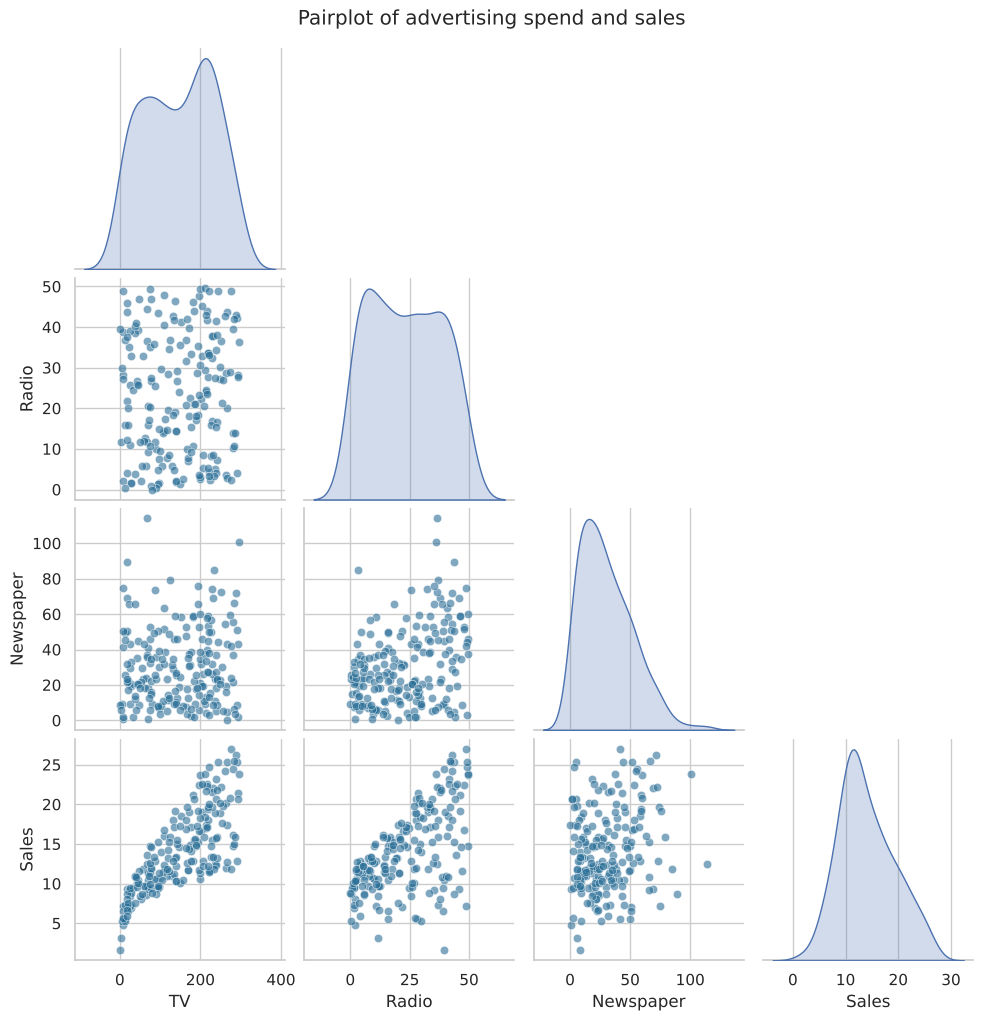

In [5]:
# Pairplot of all features
g = sns.pairplot(df, diag_kind="kde", corner=True, plot_kws={"alpha": 0.6, "color": "#2A6F97"})
g.figure.suptitle("Pairplot of advertising spend and sales", y=1.02)
g.savefig(OUT / "pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Sales vs each advertising channel

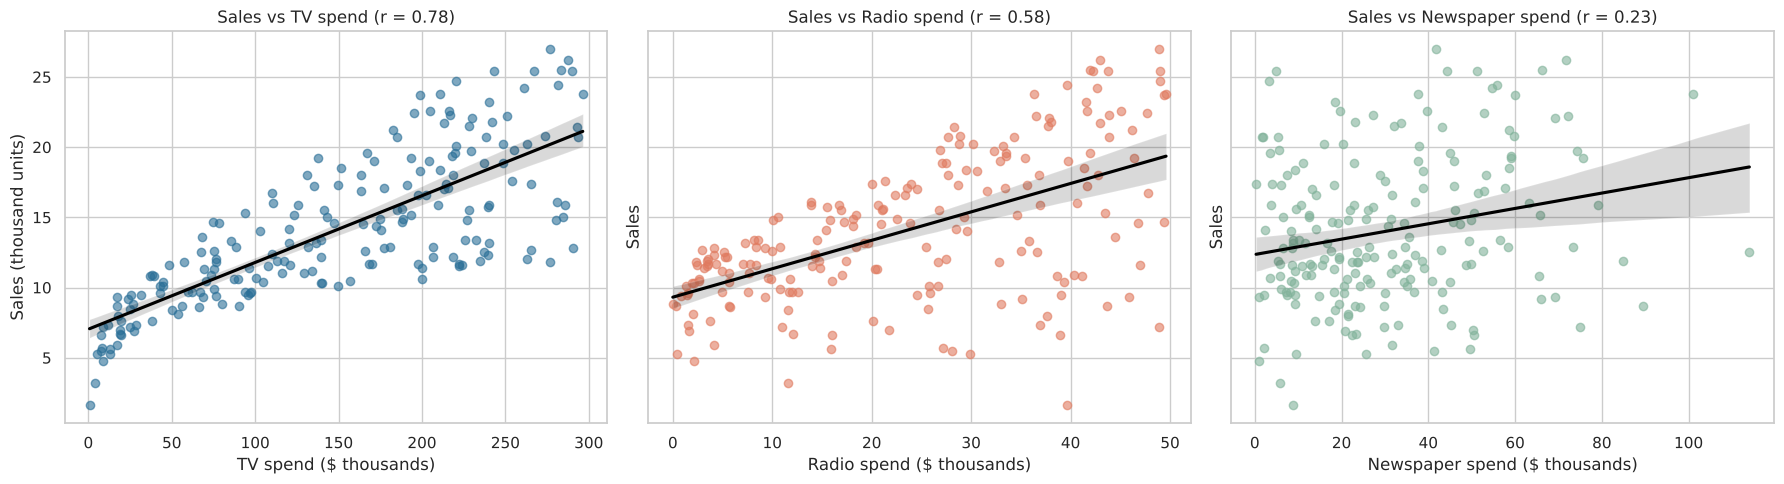

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, col, color in zip(axes, ["TV", "Radio", "Newspaper"], ["#2A6F97", "#E07A5F", "#81B29A"]):
    sns.regplot(data=df, x=col, y="Sales", ax=ax, color=color, scatter_kws={"alpha": 0.6}, line_kws={"color": "black"})
    r = df[col].corr(df["Sales"])
    ax.set_title(f"Sales vs {col} spend (r = {r:.2f})")
    ax.set_xlabel(f"{col} spend ($ thousands)")
axes[0].set_ylabel("Sales (thousand units)")
fig.tight_layout()
fig.savefig(OUT / "sales_vs_channels.png", dpi=120, bbox_inches="tight")
plt.show()

- **TV** has a strong, clearly positive relationship with sales, with a slight curve (diminishing returns)
  and spread that widens as spend grows.
- **Radio** shows a moderate positive relationship.
- **Newspaper** shows only a weak relationship; the points are a broad cloud.

## 3. Correlation matrix heatmap

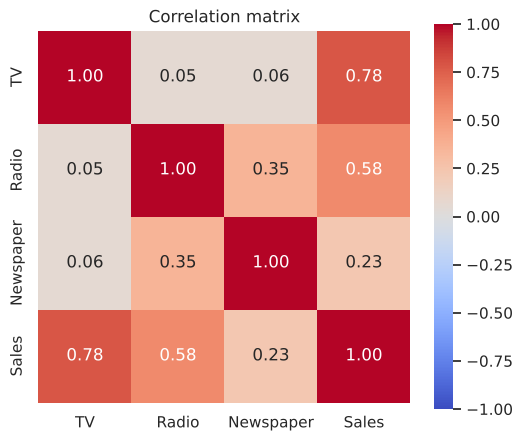

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.savefig(OUT / "correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

TV has the highest correlation with Sales (≈0.78), then Radio (≈0.58), then Newspaper (≈0.23).
Newspaper is also correlated with Radio (≈0.35), so part of its apparent link with sales may really be
Radio's effect; the regression below separates the two.

## 4. Train/test split (80/20)

In [8]:
features = ["TV", "Radio", "Newspaper"]
X, y = df[features], df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (160, 3)  Test: (40, 3)


## 5. Models
1. **Linear Regression**: baseline, assumes each channel adds a fixed amount of sales per dollar.
2. **Polynomial Regression (degree 2)**: adds squared terms and *interaction* terms such as TV × Radio,
   so it can capture diminishing returns and synergy between channels.
3. **Random Forest Regressor**: a non-linear ensemble of decision trees.

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (deg 2)": make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
}

def evaluate(name, model):
    pred = model.predict(X_test)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    return {
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "CV_R2_mean": cv_r2.mean(),
    }

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, model))

results = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results.to_csv(OUT / "model_comparison.csv", index=False)
results.round(4)

,model,MAE,RMSE,R2,CV_R2_mean
0,Polynomial Regression (deg 2),0.5262,0.6426,0.9869,0.9772
1,Random Forest,0.6139,0.7406,0.9826,0.9701
2,Linear Regression,1.4608,1.7816,0.8994,0.8595


## 6. Evaluation
- **MAE**: average absolute error, in thousands of units.
- **RMSE**: like MAE but penalises large errors more.
- **R²**: share of the variance in sales the model explains (1.0 = perfect).

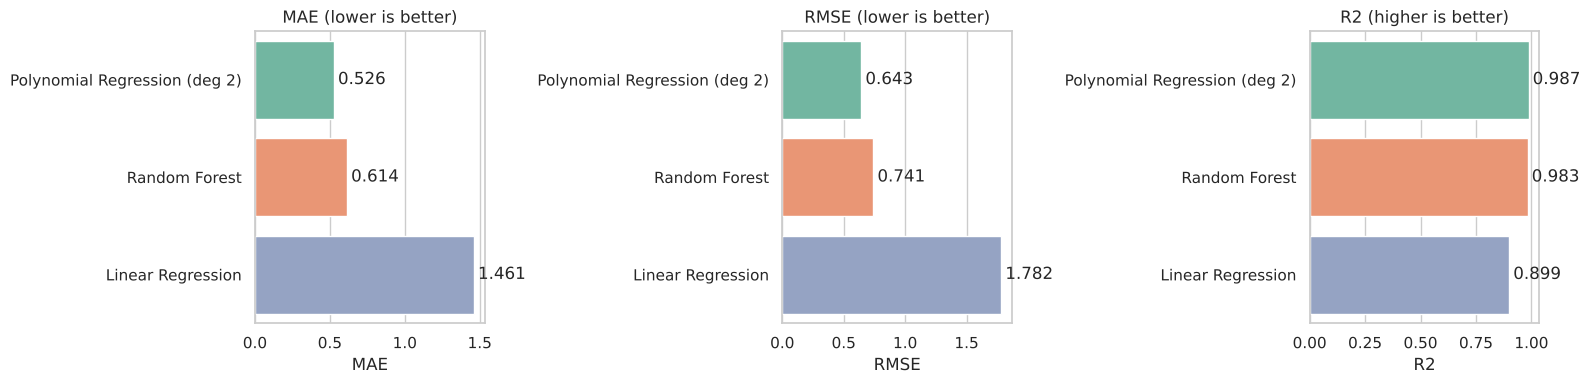

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(data=results, x=metric, y="model", hue="model", palette="Set2", ax=ax, legend=False)
    ax.set_title(metric + (" (higher is better)" if metric == "R2" else " (lower is better)"))
    ax.set_ylabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", padding=3)
fig.tight_layout()
fig.savefig(OUT / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

Best model: Polynomial Regression (deg 2)


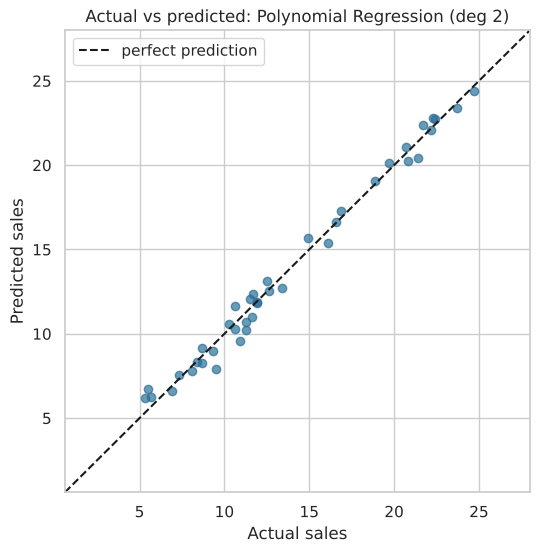

In [11]:
best_name = results.loc[0, "model"]
best_model = models[best_name]
best_pred = best_model.predict(X_test)
print("Best model:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.7, color="#2A6F97")
lims = [y.min() - 1, y.max() + 1]
plt.plot(lims, lims, "k--", label="perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual sales"); plt.ylabel("Predicted sales")
plt.title(f"Actual vs predicted: {best_name}")
plt.legend()
plt.savefig(OUT / "actual_vs_predicted.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Residual analysis
Residual = actual − predicted. If a model has captured the pattern in the data, residuals should be
scattered randomly around zero with no visible shape. We plot them for the best model and, for
comparison, the linear baseline.

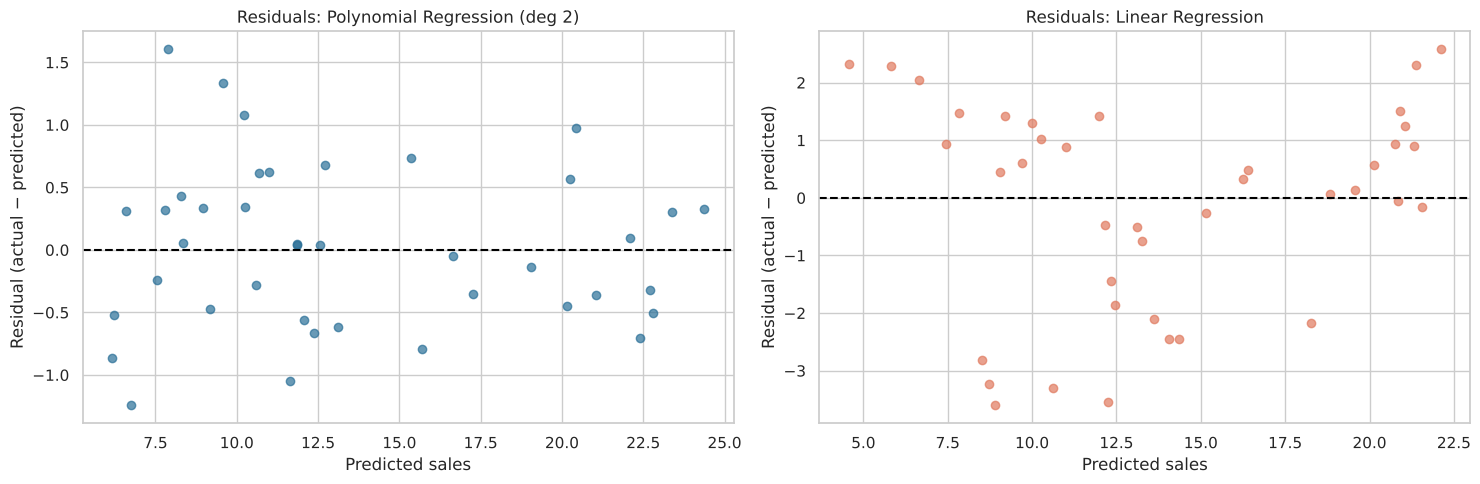

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, [best_name, "Linear Regression"]):
    pred = models[name].predict(X_test)
    resid = y_test - pred
    ax.scatter(pred, resid, alpha=0.7, color="#E07A5F" if name == "Linear Regression" else "#2A6F97")
    ax.axhline(0, color="black", linestyle="--")
    ax.set_xlabel("Predicted sales"); ax.set_ylabel("Residual (actual − predicted)")
    ax.set_title(f"Residuals: {name}")
fig.tight_layout()
fig.savefig(OUT / "residual_plots.png", dpi=120, bbox_inches="tight")
plt.show()

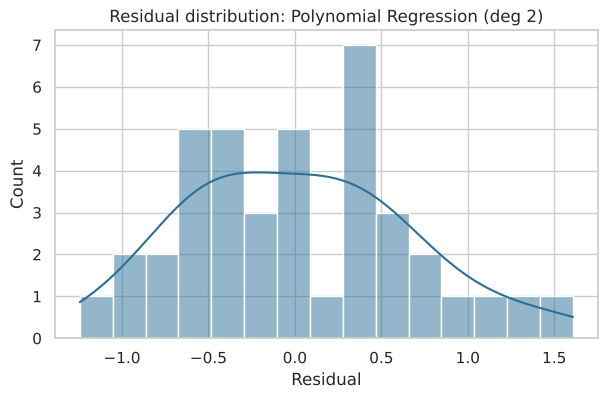

In [13]:
plt.figure(figsize=(7, 4))
sns.histplot(y_test - best_pred, kde=True, bins=15, color="#2A6F97")
plt.title(f"Residual distribution: {best_name}")
plt.xlabel("Residual")
plt.savefig(OUT / "residual_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Are the errors random or systematic?**
- **Linear Regression** shows a clear **U-shaped pattern**: it over-predicts mid-range sales and
  under-predicts both very low and very high sales. That is a *systematic* error caused by the
  non-linearity and the TV × Radio interaction that a straight-line model cannot represent.
- The **best model's** residuals are small, centred on zero and show no obvious pattern across the range
  of predictions, so its remaining errors look **random**, i.e. noise the features cannot explain.

## 8. Which advertising channel has the greatest impact on sales?

In [14]:
# (a) Linear Regression coefficients: extra sales (thousand units) per extra $1k spent on each channel
lin = models["Linear Regression"]
coef = pd.Series(lin.coef_, index=features)
print(f"Intercept: {lin.intercept_:.3f}")
print("Coefficients (sales units per $1k):\n", coef.round(4))

# (b) Standardised coefficients: effect of a one-standard-deviation increase in spend, comparable across channels
std_coef = coef * X_train.std()
# (c) Random Forest feature importance
rf_imp = pd.Series(models["Random Forest"].feature_importances_, index=features)

impact = pd.DataFrame({"linear_coef": coef, "standardised_coef": std_coef, "rf_importance": rf_imp}).round(4)
impact.to_csv(OUT / "channel_impact.csv")
impact

Intercept: 2.979
Coefficients (sales units per $1k):
 TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64


,linear_coef,standardised_coef,rf_importance
TV,0.0447,3.7760,0.6254
Radio,0.1892,2.8011,0.3618
Newspaper,0.0028,0.0562,0.0128


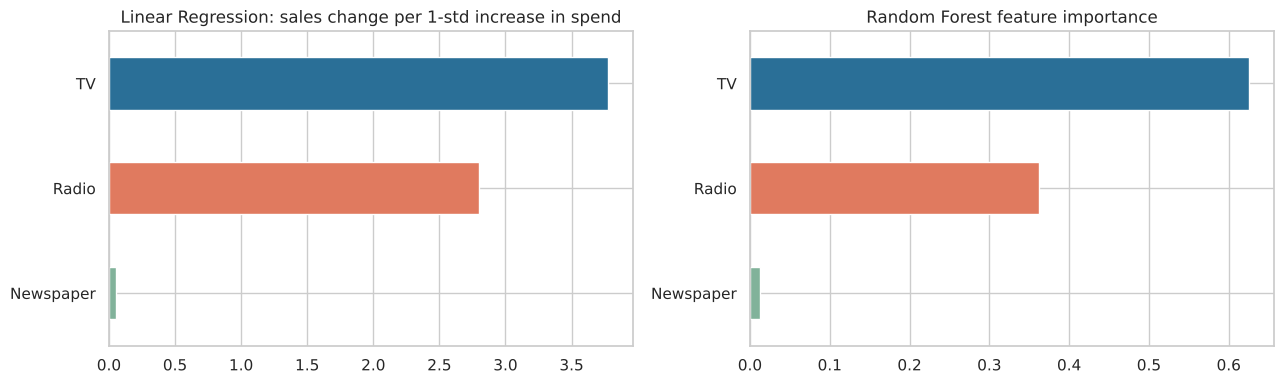

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
std_coef.sort_values().plot.barh(ax=axes[0], color=["#81B29A", "#E07A5F", "#2A6F97"])
axes[0].set_title("Linear Regression: sales change per 1-std increase in spend")
rf_imp.sort_values().plot.barh(ax=axes[1], color=["#81B29A", "#E07A5F", "#2A6F97"])
axes[1].set_title("Random Forest feature importance")
fig.tight_layout()
fig.savefig(OUT / "channel_impact.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation**
- **Per dollar, Radio is the most effective channel**: each extra $1k on Radio adds roughly 0.19 thousand
  units, versus about 0.045 for TV.
- **Overall, TV has the greatest impact on sales**: budgets vary far more on TV, so a typical
  (one-standard-deviation) change in TV spend moves sales the most, and the Random Forest attributes most
  of its predictive power to TV.
- **Newspaper has essentially no effect** once TV and Radio are accounted for (coefficient ≈ 0). Its
  weak raw correlation with sales comes from being correlated with Radio spend.
- The better fit of the polynomial model shows **TV and Radio work together**: spending on both lifts
  sales more than the sum of each alone.

**Business takeaway:** keep investing in TV for reach, add Radio alongside it for the synergy, and move
newspaper budget into those two channels.

In [16]:
# Predict sales for a new advertising plan with the best model
plans = pd.DataFrame({"TV": [150, 50, 250], "Radio": [25, 40, 5], "Newspaper": [20, 10, 60]})
plans["Predicted_Sales"] = best_model.predict(plans[features]).round(2)
plans

,TV,Radio,Newspaper,Predicted_Sales
0,150,25,20,15.14
1,50,40,10,10.56
2,250,5,60,12.37
